# Pair 1: Shelf monitoring, YOLO26s (System A) vs RF-DETR Nano (System B)

Store staff walk the aisles to find empty facings and count stock. If a detector can find every product in a shelf
photo, the gap check and the count can be done from photos. Shelf photos are hard for detectors because there are
about 150 small, tightly packed products in each one.

- System A, YOLO26s (Ultralytics, 2026): one-stage CNN detector with an NMS-free head.
- System B, RF-DETR Nano (Roboflow, 2025): detection transformer with a DINOv2 backbone and set prediction.

Both are fine-tuned on the same SKU-110K subset (Goldman et al., 2019) with three seeds. I measure COCO mAP, then
precision, recall, F1 and counting error at a working threshold, plus speed and a simple cost comparison.

To run on Kaggle: GPU T4 x2, Internet on, add a SKU-110K dataset as input, then Save & Run All (about 60 min).

## Setup
Install the pinned packages, import the libraries and fix the settings shared by both detectors.

In [ ]:
# install the pinned versions used for this run
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.189", "rfdetr[train]==1.11.2", "pycocotools"],
               check=True, capture_output=True)

In [ ]:
# libraries
import contextlib, io, json, random, shutil, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageDraw
from scipy.stats import wilcoxon

# output folder, system names and the settings shared by both detectors
OUT = Path("/kaggle/working/pair1")
OUT.mkdir(parents=True, exist_ok=True)
A, B = "YOLO26s", "RF-DETR Nano"
SEEDS = [0, 1, 2]
N_TRAIN, N_VAL, N_TEST = 500, 100, 150
IMGSZ, EPOCHS, MAX_DET = 640, 12, 300      # same for both; RF-DETR Nano has 300 queries so YOLO gets the same cap
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
print(torch.cuda.get_device_name(0))

Tesla T4


## Data
A fixed random subset of each official SKU-110K split. Photos are resized once (long side 1280) and written in YOLO
format so both detectors train on exactly the same files.

In [ ]:
# find the SKU-110K copy attached to the notebook (CSV or YOLO label format)
def split_dir(paths, split):
    # pick the images folder for one split (train / val or valid / test)
    names = {"train": ["train"], "val": ["val", "valid", "validation"], "test": ["test"]}[split]
    return next((p for p in paths if p.name == "images" and p.parent.name.lower() in names), None) \
        or next((p for p in paths if p.parent.name == "images" and p.name.lower() in names), None)


def find_sku110k():
    inp = Path("/kaggle/input")
    # 1) original format: annotations_<split>.csv plus a folder of photos
    for csv in inp.rglob("*.csv"):
        if csv.name.lower() == "annotations_test.csv":
            first = pd.read_csv(csv, header=None, nrows=1)[0][0]
            img = next(inp.rglob(first), None)
            if img is not None:
                return "csv", csv.parent, img.parent
    # 2) YOLO format: images/<split> and labels/<split> (or <split>/images and <split>/labels)
    dirs = [p for p in inp.rglob("*") if p.is_dir()]
    found = {s: split_dir(dirs, s) for s in ("train", "val", "test")}
    if all(found.values()):
        return "yolo", found, None
    return None, None, None


# use the attached copy, or download the official archive if none is found
fmt, where, img_dir = find_sku110k()
if fmt is None:
    import tarfile, urllib.request
    print("no usable SKU-110K copy in /kaggle/input, downloading the official archive (about 25 min)")
    archive = Path("/tmp/SKU110K_fixed.tar.gz")
    with urllib.request.urlopen("http://trax-geometry.s3.amazonaws.com/cvpr_challenge/SKU110K_fixed.tar.gz") as r, open(archive, "wb") as f:
        shutil.copyfileobj(r, f, length=16 << 20)
    with tarfile.open(archive) as tar:
        tar.extractall("/tmp", filter="data")
    archive.unlink()
    fmt, where, img_dir = "csv", Path("/tmp/SKU110K_fixed/annotations"), Path("/tmp/SKU110K_fixed/images")
print("format:", fmt, "|", where)


def photos_and_boxes(split):
    # list of (photo path, function that returns its boxes in pixels as x1 y1 x2 y2)
    if fmt == "csv":
        ann = pd.read_csv(where / f"annotations_{split}.csv", header=None, names=["image", "x1", "y1", "x2", "y2", "cls", "w", "h"])
        groups = dict(tuple(ann.groupby("image")))
        items = []
        for name, rows in groups.items():
            def boxes(img, rows=rows):
                if img.size != (rows.w.iloc[0], rows.h.iloc[0]):    # a few photos don't match their labels
                    return None
                return rows[["x1", "y1", "x2", "y2"]].to_numpy(float)
            items.append((img_dir / name, boxes))
        return items
    items = []
    for path in sorted(where[split].glob("*.jpg")):
        label = Path(str(path).replace("/images/", "/labels/")).with_suffix(".txt")
        def boxes(img, label=label):
            if not label.exists():
                return None
            r = np.loadtxt(label, ndmin=2)[:, 1:5]
            W, H = img.size
            return np.c_[(r[:, 0] - r[:, 2] / 2) * W, (r[:, 1] - r[:, 3] / 2) * H, (r[:, 0] + r[:, 2] / 2) * W, (r[:, 1] + r[:, 3] / 2) * H]
        items.append((path, boxes))
    return items


# build the working dataset: a fixed random subset of each split (seed 0), photos resized to a long side of 1280 px,
# labels written in YOLO format, and the test labels also written in COCO format for pycocotools
DATA = Path("/tmp/sku")
shutil.rmtree(DATA, ignore_errors=True)
coco_gt = {"images": [], "annotations": [], "categories": [{"id": 1, "name": "product"}]}
gt = {}   # (folder, photo) -> true boxes

for split, folder, n in [("train", "train", N_TRAIN), ("val", "valid", N_VAL), ("test", "test", N_TEST)]:
    items = sorted(photos_and_boxes(split), key=lambda x: x[0].name)
    random.Random(0).shuffle(items)
    (DATA / folder / "images").mkdir(parents=True)
    (DATA / folder / "labels").mkdir(parents=True)
    kept = 0
    for path, get_boxes in items:
        if kept == n:
            break
        try:
            img = Image.open(path).convert("RGB")
        except OSError:
            continue
        b = get_boxes(img)
        if b is None or len(b) == 0:
            continue
        name = path.name
        s = 1280 / max(img.size)
        w, h = round(img.width * s), round(img.height * s)
        img.resize((w, h)).save(DATA / folder / "images" / name, quality=95)
        b = b * s
        gt[(folder, name)] = b
        lines = [f"0 {(x1 + x2) / 2 / w} {(y1 + y2) / 2 / h} {(x2 - x1) / w} {(y2 - y1) / h}" for x1, y1, x2, y2 in b]
        (DATA / folder / "labels" / (path.stem + ".txt")).write_text("\n".join(lines))
        if folder == "test":
            coco_gt["images"].append({"id": kept + 1, "file_name": name, "width": w, "height": h})
            for x1, y1, x2, y2 in b:
                coco_gt["annotations"].append({"id": len(coco_gt["annotations"]) + 1, "image_id": kept + 1, "category_id": 1,
                                               "iscrowd": 0, "bbox": [x1, y1, x2 - x1, y2 - y1], "area": (x2 - x1) * (y2 - y1)})
        kept += 1
    print(split, kept, "photos")

(DATA / "data.yaml").write_text(f"path: {DATA}\ntrain: train/images\nval: valid/images\nnames:\n  0: product\n")
(DATA / "test_coco.json").write_text(json.dumps(coco_gt))
print("products per test photo:", round(len(coco_gt["annotations"]) / N_TEST, 1))

format: yolo | {'train': PosixPath('/kaggle/input/datasets/thedatasith/sku110k-annotations/SKU110K_fixed/images/train'), 'val': PosixPath('/kaggle/input/datasets/thedatasith/sku110k-annotations/SKU110K_fixed/images/val'), 'test': PosixPath('/kaggle/input/datasets/thedatasith/sku110k-annotations/SKU110K_fixed/images/test')}
train 500 photos
val 100 photos
test 150 photos
products per test photo: 143.0


## Training and prediction
Both start from COCO-pretrained weights with the same photos, input size, epochs and seed. RF-DETR needs batch 4 with
4 accumulation steps to fit on the T4 (effective batch 16); YOLO uses batch 8. Last epoch for both, no early stopping.
Predictions are kept down to confidence 0.001 so mAP sees the full ranking. The training logs are long, so they are
written to `train_log.txt` instead of being shown here.

In [ ]:
%%capture train_output
# train each detector with each seed, then predict on the validation and test photos
import os
os.environ["YOLO_VERBOSE"] = "False"
from rfdetr import RFDETRNano
from ultralytics import YOLO


# returns a predict(path) function giving boxes and confidences for one photo
def train(system, seed):
    if system == A:
        m = YOLO("yolo26s.pt")
        m.train(data=str(DATA / "data.yaml"), imgsz=IMGSZ, epochs=EPOCHS, batch=8, seed=seed, deterministic=True,
                patience=0, max_det=MAX_DET, project="/tmp/runs", name=f"yolo{seed}", exist_ok=True, plots=False, verbose=False)
        m = YOLO(f"/tmp/runs/yolo{seed}/weights/last.pt")

        def predict(path):
            r = m.predict(str(path), imgsz=IMGSZ, conf=0.001, max_det=MAX_DET, nms=False, verbose=False)[0].boxes
            return r.xyxy.cpu().numpy(), r.conf.cpu().numpy()
    else:
        m = RFDETRNano()
        m.train(dataset_dir=str(DATA), dataset_file="yolo", resolution=IMGSZ, epochs=EPOCHS, batch_size=4, grad_accum_steps=4,
                multi_scale="off", early_stopping=False, seed=seed, tensorboard=False, output_dir=f"/tmp/runs/rfdetr{seed}")

        def predict(path):
            d = m.predict(Image.open(path).convert("RGB"), threshold=0.001)
            top = np.argsort(-d.confidence)[:MAX_DET]
            return d.xyxy[top], d.confidence[top]
    return predict


# train both detectors for every seed and keep all predictions, sorted by confidence
preds, models, train_min = {}, {}, []
for seed in SEEDS:
    for system in (A, B):
        random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
        t0 = time.time()
        predict = train(system, seed)
        train_min.append({"seed": seed, "system": system, "minutes": (time.time() - t0) / 60})
        for (folder, name) in gt:
            if folder != "train":
                boxes, conf = predict(DATA / folder / "images" / name)
                order = np.argsort(-conf)
                preds[(seed, system, folder, name)] = (boxes[order], conf[order])
        # the seed 0 models are kept for the speed test
        if seed == 0:
            models[system] = predict
        torch.cuda.empty_cache()

In [ ]:
# save the training log and the training time per run
(OUT / "train_log.txt").write_text(train_output.stdout + train_output.stderr)
train_min = pd.DataFrame(train_min)
train_min.to_csv(OUT / "training_time.csv", index=False)
display(train_min.round(1))

,seed,system,minutes
0,0,YOLO26s,3.4
1,0,RF-DETR Nano,11.8
2,1,YOLO26s,2.6
3,1,RF-DETR Nano,11.6
4,2,YOLO26s,2.6
5,2,RF-DETR Nano,11.9


## Metrics
- COCO mAP (IoU 0.50 to 0.95) and AP50 with up to 300 detections, the usual benchmark numbers.
- At one working threshold (chosen on the validation photos for best F1), for every test photo: precision, recall
  and F1 at IoU 0.5, and counting error = |found - true| / true. A stock audit runs at one threshold, so these are
  closer to what the store needs than mAP.

In [ ]:
# per-photo scores at a working threshold, and COCO mAP / AP50 over all detections
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval


# IoU between every predicted box and every true box
def iou(a, b):
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = lambda z: (z[:, 2] - z[:, 0]) * (z[:, 3] - z[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter)


# precision, recall, F1 and counting error per photo, matching boxes at IoU 0.5
def photo_scores(seed, system, folder, thr):
    rows = []
    for (f, name), true in gt.items():
        if f != folder:
            continue
        boxes, conf = preds[(seed, system, folder, name)]
        boxes = boxes[conf >= thr]
        tp, used = 0, np.zeros(len(true), bool)
        if len(boxes):
            m = iou(boxes, true)
            for i in range(len(boxes)):           # greedy match in score order
                j = np.argmax(np.where(used, -1, m[i]))
                if m[i, j] >= 0.5 and not used[j]:
                    used[j], tp = True, tp + 1
        p, r = tp / max(len(boxes), 1), tp / len(true)
        rows.append({"seed": seed, "system": system, "photo": name, "true": len(true), "found": len(boxes), "precision": p,
                     "recall": r, "f1": 2 * p * r / (p + r) if tp else 0, "count_error": abs(len(boxes) - len(true)) / len(true)})
    return pd.DataFrame(rows)


# COCO mAP (IoU 0.50 to 0.95) and AP50 with up to MAX_DET detections per photo
def coco_map(seed, system):
    dets = [{"image_id": im["id"], "category_id": 1, "score": float(c), "bbox": [float(x1), float(y1), float(x2 - x1), float(y2 - y1)]}
            for im in coco_gt["images"] for (x1, y1, x2, y2), c in zip(*preds[(seed, system, "test", im["file_name"])])]
    with contextlib.redirect_stdout(io.StringIO()):
        ev = COCOeval(COCO(str(DATA / "test_coco.json")), COCO(str(DATA / "test_coco.json")).loadRes(dets), "bbox")
        ev.params.maxDets = [1, 100, MAX_DET]      # AP in summarize() uses the last value
        ev.evaluate(); ev.accumulate(); ev.summarize()
    return ev.stats[0], ev.stats[1]


# threshold picked on the validation photos (best mean F1), then applied to the test photos
photos, overall = [], []
for seed in SEEDS:
    for system in (A, B):
        grid = np.arange(0.05, 0.95, 0.05).round(2)
        thr = grid[np.argmax([photo_scores(seed, system, "valid", t).f1.mean() for t in grid])]
        photos.append(photo_scores(seed, system, "test", thr))
        mAP, ap50 = coco_map(seed, system)
        overall.append({"seed": seed, "system": system, "threshold": thr, "mAP": mAP, "AP50": ap50})
photos = pd.concat(photos)
overall = pd.DataFrame(overall)
photos.to_csv(OUT / "per_photo.csv", index=False)

## Results
Every seed separately, then the mean and standard deviation over seeds. The paired test compares the two detectors
photo by photo on the same 150 test photos (each photo averaged over the three seeds).

In [ ]:
# results for every seed, then mean and SD over the three seeds
by_seed = photos.groupby(["seed", "system"])[["precision", "recall", "f1", "count_error"]].mean().reset_index().merge(overall)
by_seed.to_csv(OUT / "results_by_seed.csv", index=False)
display(by_seed.round(4))
display(by_seed.groupby("system")[["f1", "count_error", "mAP"]].agg(["mean", "std"]).round(4))

# paired Wilcoxon test over the 150 test photos (each photo averaged over the three seeds)
avg = photos.groupby(["system", "photo"])[["f1", "count_error", "recall", "precision"]].mean()
paired = []
for metric in ["precision", "recall", "f1", "count_error"]:
    d = avg.loc[A, metric] - avg.loc[B, metric]
    paired.append({"metric": metric, A: avg.loc[A, metric].mean(), B: avg.loc[B, metric].mean(), "A minus B": d.mean(),
                   "photos where A is better": ((d < 0) if metric == "count_error" else (d > 0)).mean(), "Wilcoxon p": wilcoxon(d).pvalue})
paired = pd.DataFrame(paired)
paired.to_csv(OUT / "paired_test.csv", index=False)
display(paired.round(4))

,seed,system,precision,recall,f1,count_error,threshold,mAP,AP50
0,0,RF-DETR Nano,0.8429,0.8266,0.8299,0.1065,0.40,0.3729,0.8353
1,0,YOLO26s,0.8150,0.7997,0.7993,0.1313,0.25,0.3583,0.8220
2,1,RF-DETR Nano,0.8428,0.8259,0.8297,0.1049,0.40,0.3708,0.8360
3,1,YOLO26s,0.8188,0.7908,0.7949,0.1408,0.30,0.3579,0.8132
4,2,RF-DETR Nano,0.8434,0.8260,0.8301,0.1069,0.40,0.3717,0.8354
5,2,YOLO26s,0.8182,0.7920,0.7956,0.1356,0.25,0.3573,0.8139


f1         count_error             mAP        
                mean     std        mean     std    mean     std
system                                                          
RF-DETR Nano  0.8299  0.0002      0.1061  0.0010  0.3718  0.0010
YOLO26s       0.7966  0.0024      0.1359  0.0048  0.3579  0.0005

,metric,YOLO26s,RF-DETR Nano,A minus B,photos where A is better,Wilcoxon p
0,precision,0.8173,0.8430,-0.0257,0.2667,0.0
1,recall,0.7942,0.8262,-0.0320,0.2200,0.0
2,f1,0.7966,0.8299,-0.0332,0.1867,0.0
3,count_error,0.1359,0.1061,0.0298,0.3267,0.0


## Shelf density
Split by how many products the photo really has, since density is what makes this task hard.

In [ ]:
# results by shelf density (true products per photo)
photos["density"] = pd.cut(photos["true"], [0, 100, 200, 1000], labels=["up to 100", "100 to 200", "over 200"])
density = photos.groupby(["density", "system"], observed=True)[["recall", "f1", "count_error"]].mean().round(4)
density.to_csv(OUT / "by_density.csv")
display(density)

recall      f1  count_error
density    system                                   
up to 100  RF-DETR Nano  0.7789  0.7560       0.1530
           YOLO26s       0.6721  0.6709       0.2113
100 to 200 RF-DETR Nano  0.8467  0.8470       0.0926
           YOLO26s       0.8124  0.8113       0.1253
over 200   RF-DETR Nano  0.5654  0.6419       0.2644
           YOLO26s       0.6334  0.6922       0.2252

## Speed and cost
Time per photo on the T4 (seed 0 models, 50 photos, after a warm-up). Energy uses the T4's 70 W limit, so it is an
upper bound. The cost compares checking every shelf photo by
hand with letting the detector do it, at 595 photos per store per day (derived from 35,000 products per pass and
2.5 passes a day, Supermarket News 2020, with 147 products per photo).

In [ ]:
# time per photo on the T4 with the seed 0 models (50 test photos, one warm-up photo first)
test_photos = [DATA / "test" / "images" / n for (f, n) in gt if f == "test"][:50]
cost = []
for system, predict in models.items():
    predict(test_photos[0])
    torch.cuda.synchronize(); t0 = time.time()
    for p in test_photos:
        predict(p)
    torch.cuda.synchronize()
    ms = (time.time() - t0) / len(test_photos) * 1000
    # 595 photos per store per day (see the text above)
    cost.append({"system": system, "ms per photo": ms,
                 "GPU minutes per store per day": ms * 595 / 60000,
                 "GPU cost AUD per store per day": ms * 595 / 3.6e6 * 0.99,     # AWS g4dn.xlarge, Sydney, AUD 0.99/h
                 "GPU energy Wh per store per day (max)": ms * 595 / 3.6e6 * 70,  # T4 board limit is 70 W
                 "manual hours per store per day": 595 * 50.5 / 3600,           # my own timing: 50.5 s to check one photo
                 "manual cost AUD per store per day": 595 * 50.5 / 3600 * 31.15}) # Retail Award level 1 + 12% super
cost = pd.DataFrame(cost)
cost.to_csv(OUT / "speed_cost.csv", index=False)
display(cost.round(3))

,system,ms per photo,GPU minutes per store per day,GPU cost AUD per store per day,GPU energy Wh per store per day (max),manual hours per store per day,manual cost AUD per store per day
0,YOLO26s,21.916,0.217,0.004,0.254,8.347,259.994
1,RF-DETR Nano,55.800,0.553,0.009,0.646,8.347,259.994


## Go/no-go for a store pilot
My pilot criteria: F1 of at least 0.85, counting error of at most 10% and under 200 ms per photo (mean over seeds).

In [ ]:
# my go/no-go criteria for a store pilot, using the mean over seeds
s = by_seed.groupby("system")[["f1", "count_error"]].mean().join(cost.set_index("system")["ms per photo"])
s["F1 >= 0.85"] = s.f1 >= 0.85
s["count error <= 10%"] = s.count_error <= 0.10
s["< 200 ms"] = s["ms per photo"] < 200
s.to_csv(OUT / "go_no_go.csv")
display(s.round(4))

,f1,count_error,ms per photo,F1 >= 0.85,count error <= 10%,< 200 ms
system,,,,,,
RF-DETR Nano,0.8299,0.1061,55.7999,False,False,True
YOLO26s,0.7966,0.1359,21.9158,False,False,True


## Governance and risk

| Risk | Control | Owner |
|---|---|---|
| YOLO26s is AGPL-3.0, so a closed commercial system needs an Ultralytics Enterprise licence. RF-DETR is Apache 2.0. | Legal review before the pilot | Head of legal |
| SKU-110K is research-only data | Retrain on our own labelled shelf photos before going live | ML platform lead |
| Photos can show shoppers or staff (Privacy Act 1988, APP 3 and 11) | Photograph outside trading hours or blur people; delete photos within 7 days | Privacy officer |
| Missed products on dense shelves look like gaps and cause wrong re-orders | Staff confirm every flagged gap; 20 photos checked by hand each week | Store operations manager |
| New packaging or layouts lower accuracy over time | Monthly F1 on 50 labelled photos; retrain below 0.85 | ML platform lead |


## Figures
The metric bar chart and the densest test photo with each detector's boxes (both saved to the results folder).

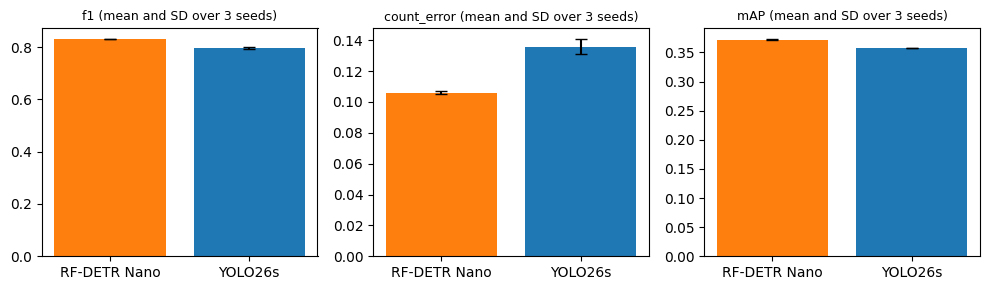

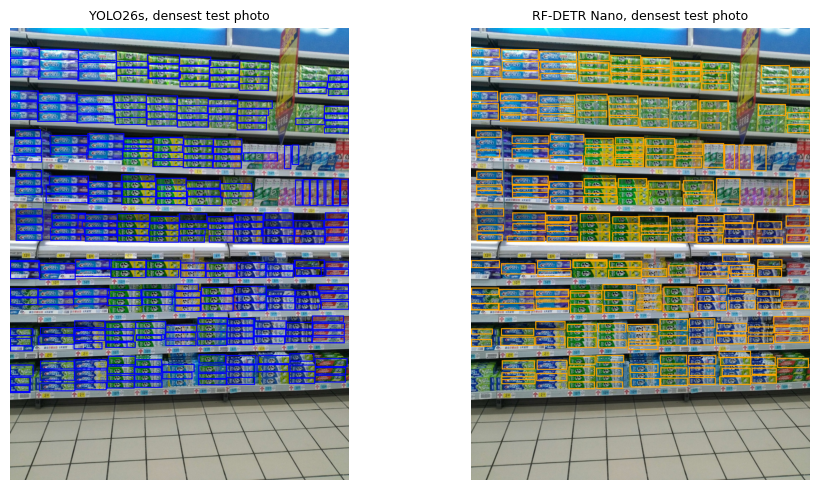

In [ ]:
# bar chart of F1, counting error and mAP (mean and SD over seeds)
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, metric in zip(axes, ["f1", "count_error", "mAP"]):
    g = by_seed.groupby("system")[metric]
    ax.bar(g.mean().index, g.mean(), yerr=g.std(), capsize=4, color=["tab:orange", "tab:blue"])
    ax.set_title(f"{metric} (mean and SD over 3 seeds)", fontsize=9)
fig.tight_layout()
fig.savefig(OUT / "fig_metrics.png", dpi=150)
plt.show()


# draw one detector's boxes above its working threshold on a test photo
def draw(system, name, colour):
    img = Image.open(DATA / "test" / "images" / name).convert("RGB")
    boxes, conf = preds[(0, system, "test", name)]
    thr = overall[(overall.seed == 0) & (overall.system == system)].threshold.iloc[0]
    d = ImageDraw.Draw(img)
    for box in boxes[conf >= thr]:
        d.rectangle(list(box), outline=colour, width=3)
    return img


# the densest test photo, side by side for both detectors
densest = photos[(photos.seed == 0) & (photos.system == A)].sort_values("true", ascending=False).photo.tolist()
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, system, colour in zip(axes, (A, B), ("blue", "orange")):
    ax.imshow(draw(system, densest[0], colour))
    ax.set_title(f"{system}, densest test photo", fontsize=9)
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUT / "fig_example.jpg", dpi=150)
plt.show()

## My ratings
The assignment specification update of October 26 allows my own evaluation as user feedback. For 10 test photos the two detectors' boxes are drawn in the same
colour and saved as X and Y in a random order; the key goes in a separate file that I only open after rating.
Question: would I trust these boxes for a stock audit? (1 = no, 5 = yes)
I also time how long it takes me to check each photo by hand (`seconds_to_check`); that is the manual-check time in
the cost table.

In [ ]:
# blind rating files: 10 test photos, both detectors drawn in the same colour, X and Y in a random order
(OUT / "rating").mkdir(exist_ok=True)
key = []
for i, name in enumerate(densest[::15][:10], 1):
    swap = random.Random(i).random() < 0.5
    x, y = (B, A) if swap else (A, B)
    draw(x, name, "lime").save(OUT / "rating" / f"item{i:02d}_X.jpg")
    draw(y, name, "lime").save(OUT / "rating" / f"item{i:02d}_Y.jpg")
    key.append({"item": i, "photo": name, "X": x, "Y": y})
# the key and an empty ratings sheet; I filled in the sheet before opening the key
pd.DataFrame(key).to_csv(OUT / "rating" / "key.csv", index=False)
pd.DataFrame({"item": range(1, 11), "score_X": "", "score_Y": "", "seconds_to_check": ""}).to_csv(OUT / "rating" / "my_ratings.csv", index=False)

**Note:** this cell ran during the Kaggle run, before I did the blind ratings, so it prints "ratings not filled in yet". That is expected: the ratings had to come after the outputs were saved and before the key was opened. My ratings and their results are in the **last cell** of this notebook, which I ran on Google Colab afterwards.

In [ ]:
# run this after filling in rating/my_ratings.csv
r = pd.read_csv(OUT / "rating" / "my_ratings.csv").merge(pd.read_csv(OUT / "rating" / "key.csv"))
if r.score_X.notna().all():
    scores = pd.concat([r[["X", "score_X"]].set_axis(["system", "score"], axis=1), r[["Y", "score_Y"]].set_axis(["system", "score"], axis=1)])
    print(scores.groupby("system").score.agg(["mean", lambda s: (s >= 4).mean()]).set_axis(["mean score", "share rated 4 or 5"], axis=1))
    print(f"my manual check: {r.seconds_to_check.mean():.1f} s per photo (the cost table uses 50.5 s, update it if different)")
else:
    print("ratings not filled in yet")

ratings not filled in yet


## Run record
Save the date, GPU, package versions, seeds and split sizes to `run_info.json`, then zip the results folder for download.

In [ ]:
# record the run settings and zip the results folder
pd.Series({"date": time.ctime(), "gpu": torch.cuda.get_device_name(0), "torch": torch.__version__,
           "ultralytics": __import__("ultralytics").__version__, "rfdetr": __import__("importlib.metadata").metadata.version("rfdetr"),
           "seeds": SEEDS, "train/val/test": [N_TRAIN, N_VAL, N_TEST]}).to_json(OUT / "run_info.json")
shutil.make_archive("/kaggle/working/pair1_results", "zip", OUT)

'/kaggle/working/pair1_results.zip'

## My ratings: results
I ran this cell on Google Colab after the Kaggle run, once I had filled in `my_ratings.csv` without looking at `key.csv`. It joins my scores to the key, compares the two detectors and adds my review time to the cost table.

In [7]:
# my ratings, added after the Kaggle run (my_ratings.csv and key.csv from rating/, speed_cost.csv from the results)
import pandas as pd
from scipy.stats import wilcoxon

# join my scores to the key so each score is linked to its detector
r = pd.read_csv("my_ratings.csv").merge(pd.read_csv("key.csv"))
scores = pd.concat([r[["X", "score_X"]].set_axis(["system", "score"], axis=1),
                    r[["Y", "score_Y"]].set_axis(["system", "score"], axis=1)])
summary = scores.groupby("system").score.agg(["mean", lambda s: (s >= 4).mean()]).set_axis(["mean score", "share rated 4 or 5"], axis=1)
display(summary.round(2))

# paired comparison of my scores, item by item
wide = scores.assign(item=list(r.item) * 2).pivot(index="item", columns="system", values="score")
d = wide["YOLO26s"] - wide["RF-DETR Nano"]
print("items where YOLO26s scored higher:", (d > 0).sum(), "| RF-DETR Nano higher:", (d < 0).sum(), "| ties:", (d == 0).sum())
print("Wilcoxon p on scores:", round(wilcoxon(d).pvalue, 3))

# review time: how long it takes me to check the detector's boxes on one photo
secs = r.seconds_to_check.mean()
cost = pd.read_csv("speed_cost.csv")
cost["review hours per store per day"] = 595 * secs / 3600
cost["review cost AUD per store per day"] = 595 * secs / 3600 * 31.15
print(f"my review time: {secs:.1f} s per photo")
display(cost.round(3))

summary.to_csv("user_ratings_summary.csv")
cost.to_csv("speed_cost_with_review.csv", index=False)

,mean score,share rated 4 or 5
system,,
RF-DETR Nano,4.6,0.9
YOLO26s,3.5,0.5


items where YOLO26s scored higher: 1 | RF-DETR Nano higher: 7 | ties: 2
Wilcoxon p on scores: 0.07
my review time: 8.9 s per photo


,system,ms per photo,GPU minutes per store per day,GPU cost AUD per store per day,GPU energy Wh per store per day (max),manual hours per store per day,manual cost AUD per store per day,review hours per store per day,review cost AUD per store per day
0,YOLO26s,21.916,0.217,0.004,0.254,8.347,259.994,1.471,45.821
1,RF-DETR Nano,55.800,0.553,0.009,0.646,8.347,259.994,1.471,45.821
